# Белорусский государственный университет информатики и радиоэлектроники
## Факультет компьютерных систем и сетей
### Кафедра программного обеспечения информационных технологий
### Дисциплина: «Методы машинного обучения»

---

# ЛАБОРАТОРНАЯ РАБОТА № 4
## «Бинарная классификация данных (Логистическая регрессия, SVM, CART)»
**Вариант 7**

**Выполнил:** студент группы 351002 Власовец Александр Игоревич  
**Проверил:** преподаватель Лебедевич Александр Витальевич  
**Исследуемый датасет:** `Bankloan.csv` (Задача банковского кредитного скоринга заемщиков)

---


## Цель лабораторной работы
Освоение практических навыков построения, оптимизации и сравнительной оценки качества моделей бинарной классификации (логистическая регрессия, метод опорных векторов SVM, дерево решений CART) на реальном датасете финансового кредитного скоринга `Bankloan.csv`.

### Задачи работы:
1. Загрузить и исследовать структуру датасета бинарной классификации.
2. Провести предварительную обработку: аудит пропусков, разделение выборки на размеченную (обучение/валидация) и неразмеченную (скоринг новых клиентов), выявление аномалий и стандартизация признаков (`StandardScaler`).
3. Построить и настроить модели бинарной классификации:
   - **Логистическая регрессия (Logistic Regression)** с анализом логистических весов и отношений шансов (Odds Ratios);
   - **Метод опорных векторов (Support Vector Machine, SVM)** с линейным и RBF ядрами, анализ опорных векторов и разделяющих границ;
   - **Дерево решений (Classification and Regression Tree, CART)** с критерием Джини и ограничением глубины.
4. Выполнить всестороннюю оценку качества классификаторов (Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC).
5. Построить и сопоставить матрицы ошибок (Confusion Matrices), ROC-кривые и Precision-Recall кривые.
6. Выполнить прикладной скоринг 450 соискателей кредита с расчетом вероятности дефолта и принятием кредитного решения.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)

# Настройка шрифтов и стилей графиков
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Calibri']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font="DejaVu Sans")

print("Библиотеки успешно импортированы. Окружение готово к работе.")


Библиотеки успешно импортированы. Окружение готово к работе.


## 1. Загрузка данных, аудит структуры и обработка пропусков

Исследуемый датасет `Bankloan.csv` содержит 1150 анкет заемщиков коммерческого банка с 8 предиктивными финансовыми признаками:
- `age`: возраст заемщика (лет);
- `ed`: уровень образования (категории 1–5);
- `employ`: стаж работы на текущем месте (лет);
- `address`: срок проживания по текущему адресу (лет);
- `income`: годовой доход (тыс. долларов);
- `debtinc`: коэффициент отношения долга к доходу (Debt-to-Income, DTI в %);
- `creddebt`: задолженность по кредитным картам (тыс. долларов);
- `othdebt`: прочие долговые обязательства (тыс. долларов);
- `default`: **целевая бинарная переменная** (0 — заемщик вернул кредит в срок, 1 — заемщик допустил дефолт/просрочку платежа).

В реальной банковской практике база состоит из двух принципиальных сегментов:
1. **700 размеченных записей** — исторические клиенты банка с известным статусом возврата кредита (517 надежных, 183 дефолтных). Используются для обучения и тестирования моделей.
2. **450 неразмеченных записей (`default = NaN`)** — соискатели новых кредитов, обратившиеся в банк. Модели должны рассчитать для них вероятность дефолта и выдать кредитную рекомендацию.


Всего анкет в базе: 1150
Историческая выборка с меткой (Train/Test): 700 клиентов
 - Класс 0 (Платежеспособные): 517 (73.9%)
 - Класс 1 (Дефолтные): 183 (26.1%)
Соискатели кредита для скоринга (Inference): 450 анкет


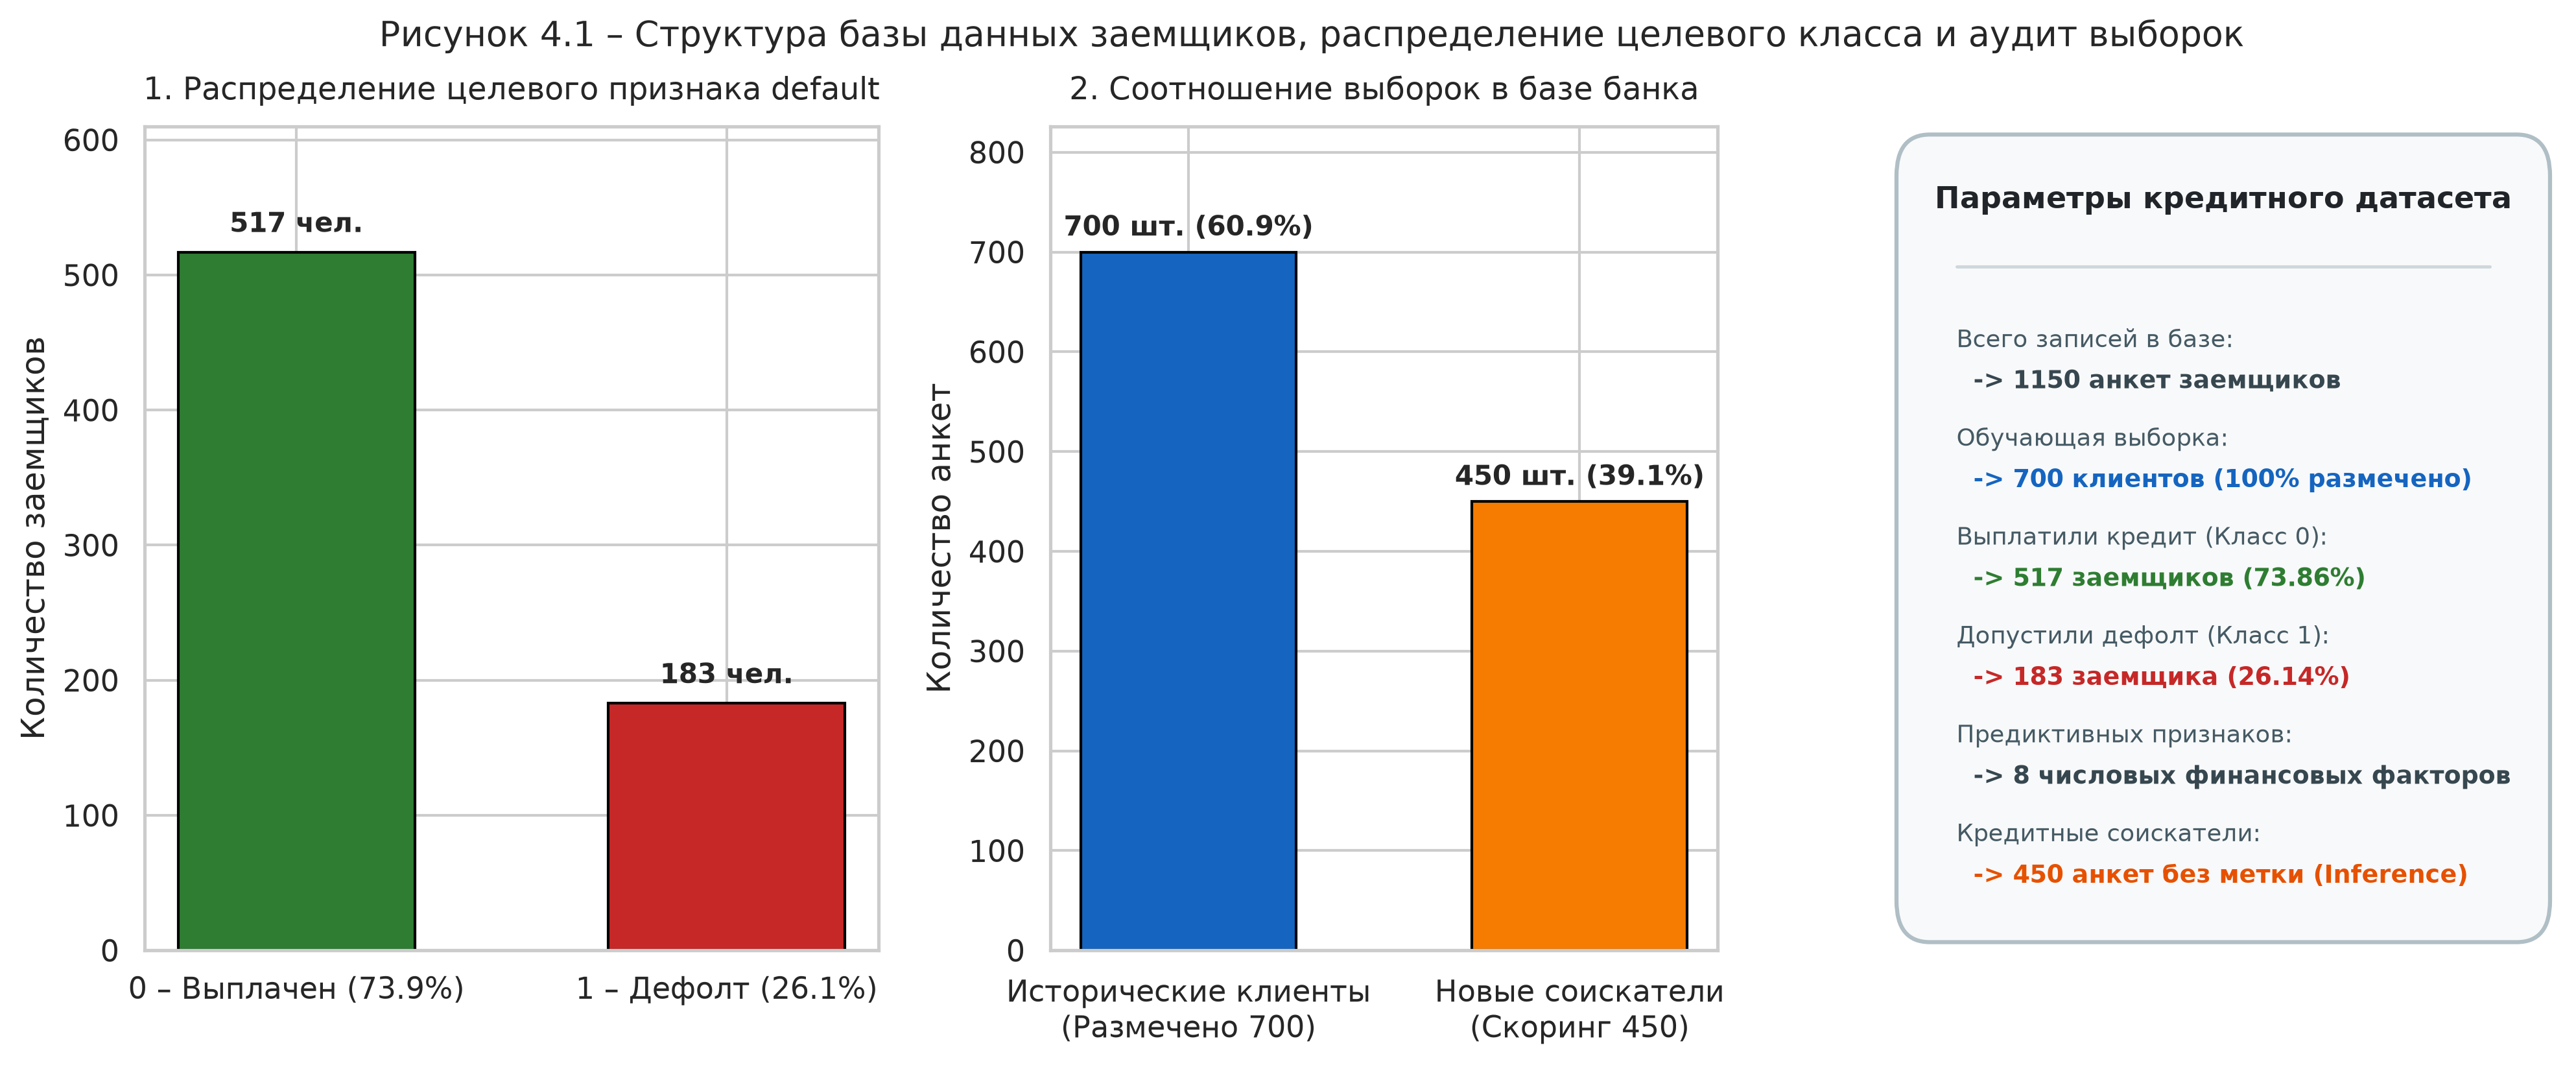

In [2]:
# Загрузка датасета
df_raw = pd.read_csv("data/Bankloan_raw.csv")
feature_cols = ['age', 'ed', 'employ', 'address', 'income', 'debtinc', 'creddebt', 'othdebt']
target_col = 'default'

# Разделение на размеченные и скоринговые данные
df_labeled = df_raw.dropna(subset=[target_col]).copy()
df_labeled[target_col] = df_labeled[target_col].astype(int)
df_unlabeled = df_raw[df_raw[target_col].isnull()].copy().drop(columns=[target_col])

print(f"Всего анкет в базе: {len(df_raw)}")
print(f"Историческая выборка с меткой (Train/Test): {len(df_labeled)} клиентов")
print(f" - Класс 0 (Платежеспособные): {(df_labeled[target_col]==0).sum()} ({ (df_labeled[target_col]==0).mean()*100:.1f}%)")
print(f" - Класс 1 (Дефолтные): {(df_labeled[target_col]==1).sum()} ({ (df_labeled[target_col]==1).mean()*100:.1f}%)")
print(f"Соискатели кредита для скоринга (Inference): {len(df_unlabeled)} анкет")


## 2. Разведочный анализ данных (EDA) и обнаружение выбросов

Для каждого из 8 числовых признаков анализируются параметры распределения: среднее $\mu$, медиана, стандартное отклонение $\sigma$, асимметрия, а также межквартильный размах по правилу Тьюки:
$$\text{IQR} = Q_3 - Q_1, \quad [\text{low}, \text{high}] = [Q_1 - 1.5 \times \text{IQR}, \; Q_3 + 1.5 \times \text{IQR}]$$

В финансовых датасетах признаки доходов (`income`) и задолженностей (`creddebt`, `othdebt`) обладают естественной правосторонней асимметрией (Heavy Right-Tail).


[age     ] Q1= 29.00, Q3= 40.00, IQR= 11.00 | Норма: [ 12.50;  56.50] | Выбросов:   0 ( 0.0%)
[ed      ] Q1=  1.00, Q3=  2.00, IQR=  1.00 | Норма: [ -0.50;   3.50] | Выбросов:  38 ( 5.4%)
[employ  ] Q1=  3.00, Q3= 12.00, IQR=  9.00 | Норма: [-10.50;  25.50] | Выбросов:  17 ( 2.4%)
[address ] Q1=  3.00, Q3= 12.00, IQR=  9.00 | Норма: [-10.50;  25.50] | Выбросов:  21 ( 3.0%)
[income  ] Q1= 24.00, Q3= 55.00, IQR= 31.00 | Норма: [-22.50; 101.50] | Выбросов:  53 ( 7.6%)
[debtinc ] Q1=  5.10, Q3= 14.22, IQR=  9.12 | Норма: [ -8.59;  27.91] | Выбросов:  20 ( 2.9%)
[creddebt] Q1=  0.39, Q3=  1.89, IQR=  1.50 | Норма: [ -1.87;   4.15] | Выбросов:  54 ( 7.7%)
[othdebt ] Q1=  1.04, Q3=  3.90, IQR=  2.86 | Норма: [ -3.25;   8.19] | Выбросов:  52 ( 7.4%)


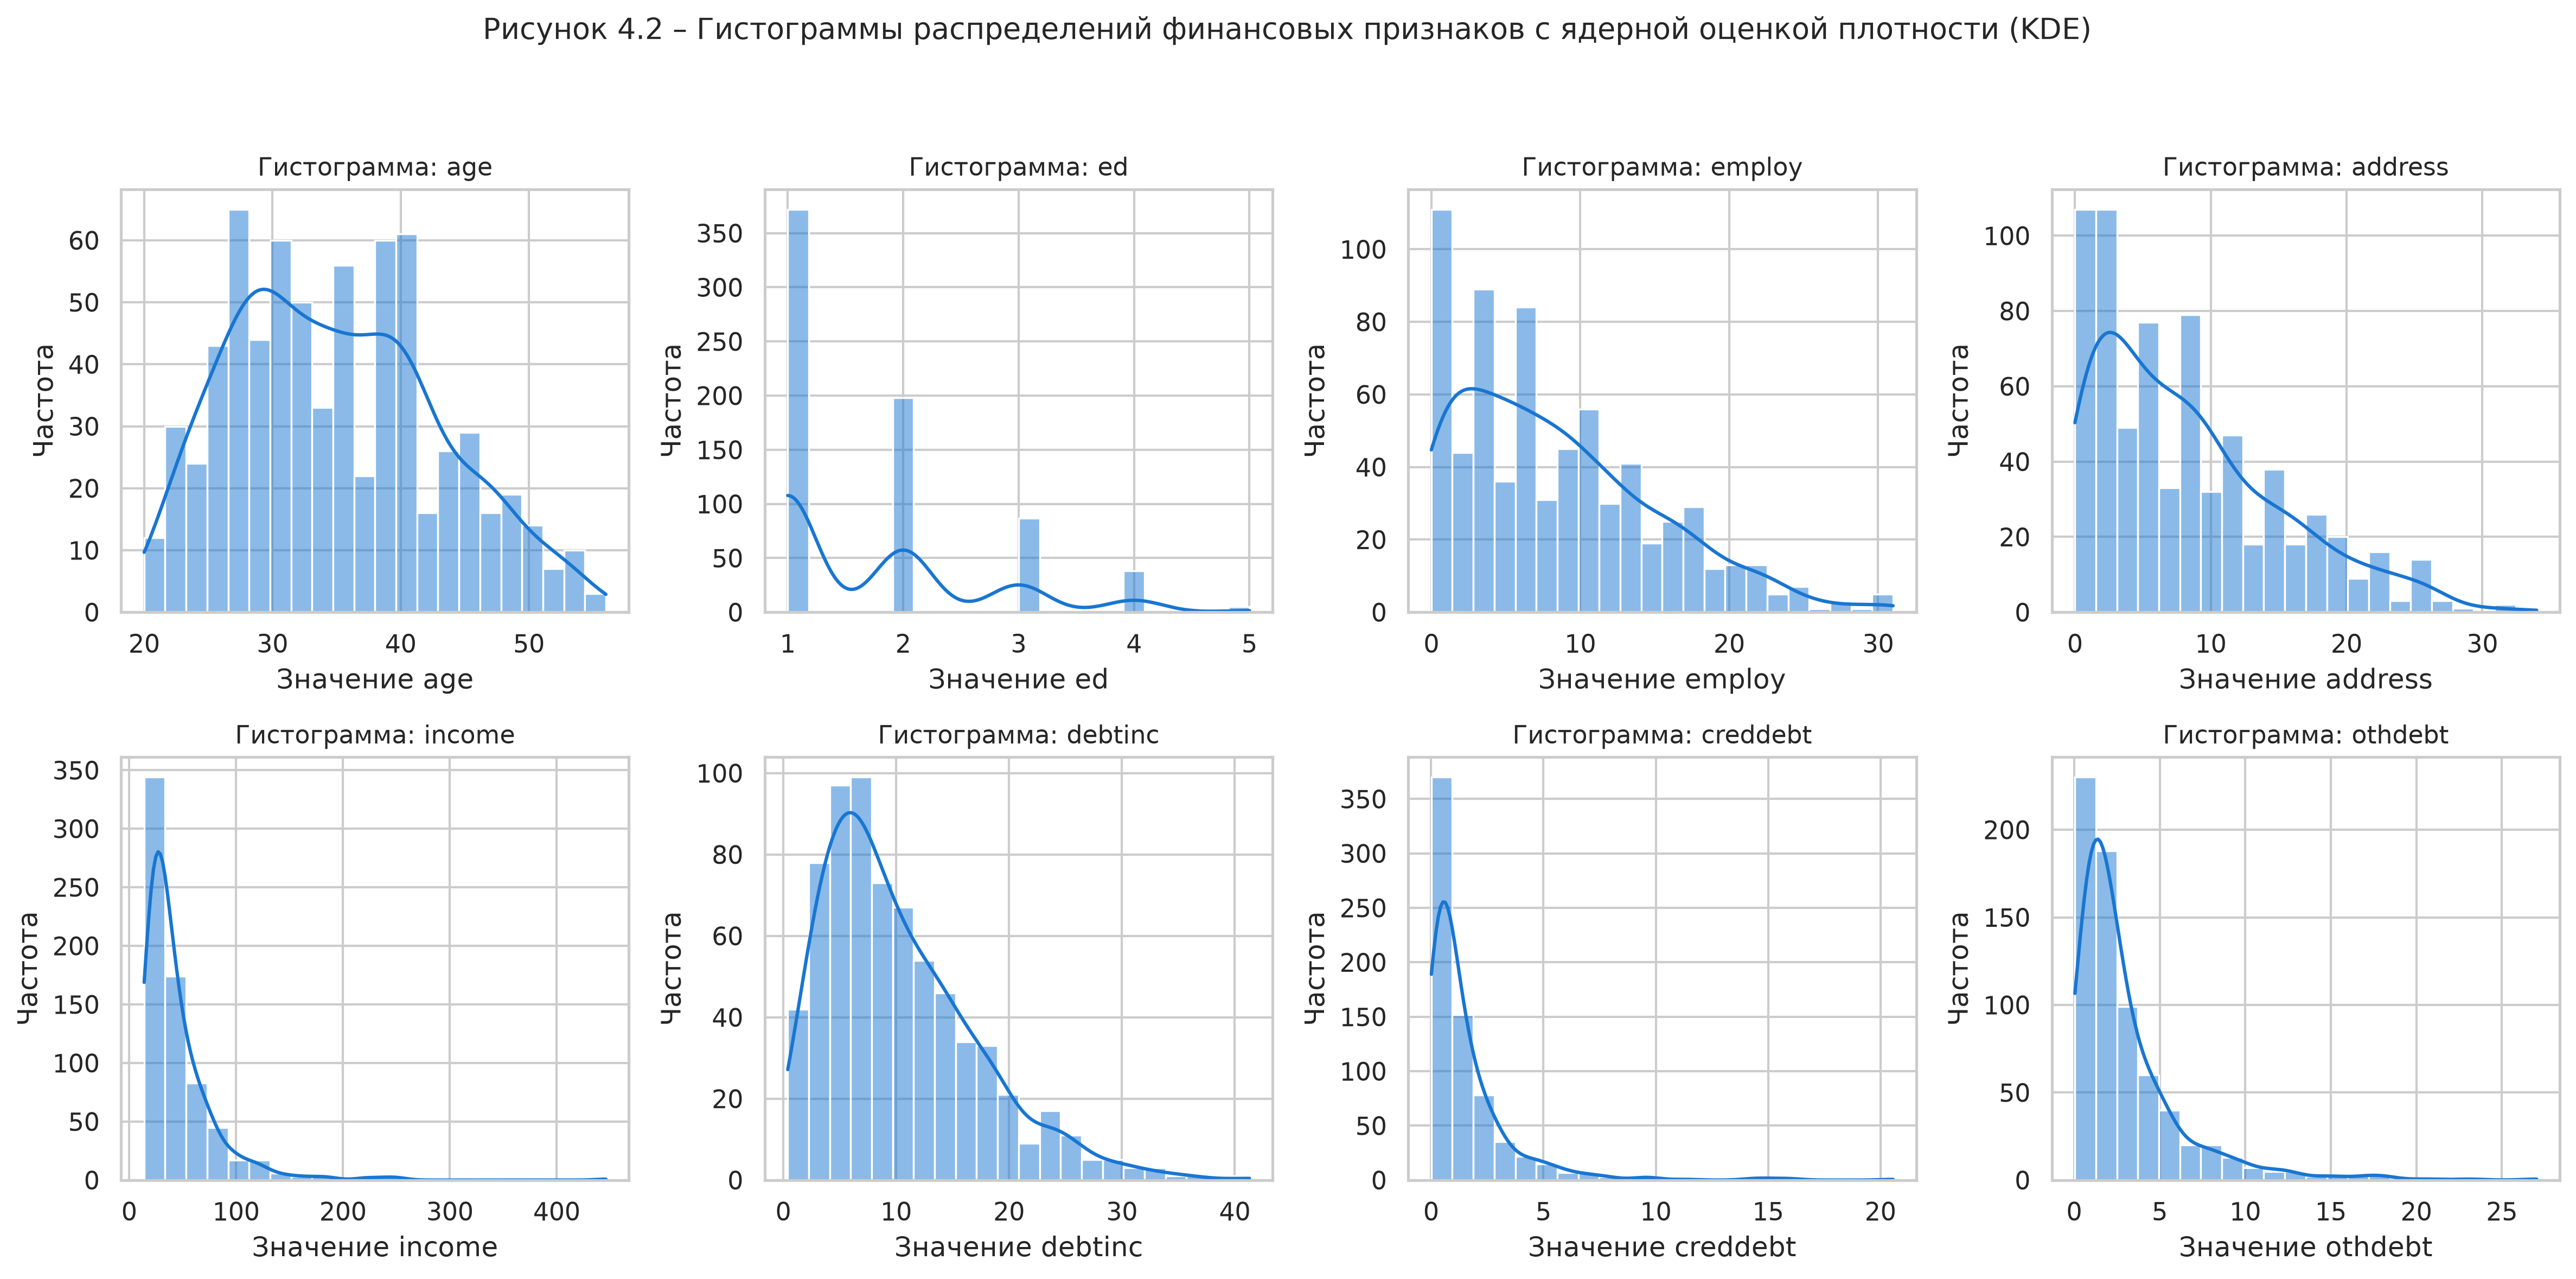

In [3]:
# Статистика выбросов по правилу Тьюки
for col in feature_cols:
    q1 = df_labeled[col].quantile(0.25)
    q3 = df_labeled[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    cnt = int(((df_labeled[col] < low) | (df_labeled[col] > high)).sum())
    print(f"[{col:8s}] Q1={q1:6.2f}, Q3={q3:6.2f}, IQR={iqr:6.2f} | Норма: [{low:6.2f}; {high:6.2f}] | Выбросов: {cnt:3d} ({cnt/len(df_labeled)*100:4.1f}%)")


## 3. Корреляционный анализ факторов кредитного риска

Рассчитана матрица парной линейной корреляции Пирсона между всеми признаками и целевым индикатором дефолта `default`.

Ключевые эмпирические зависимости:
1. `debtinc` (отношение долга к доходу) имеет **наибольшую положительную корреляцию с дефолтом ($r = +0.39$)**: чем выше доля платежей по кредитам в доходах семьи, тем выше вероятность неплатежа.
2. `creddebt` (задолженность по кредитным картам) также положительно связана с дефолтом ($r = +0.24$).
3. `employ` (стаж работы) имеет **наибольшую отрицательную корреляцию с дефолтом ($r = -0.28$)**: стабильный многолетний трудовой стаж заемщика является главным фактором надежности.
4. `address` (срок проживания по адресу) снижает риск ($r = -0.16$), подтверждая устойчивую оседлость заемщика.


Корреляция финансовых признаков с целевым признаком default:
 - debtinc   : r = +0.3896
 - creddebt  : r = +0.2447
 - othdebt   : r = +0.1457
 - ed        : r = +0.1147
 - income    : r = -0.0710
 - age       : r = -0.1377
 - address   : r = -0.1645
 - employ    : r = -0.2830


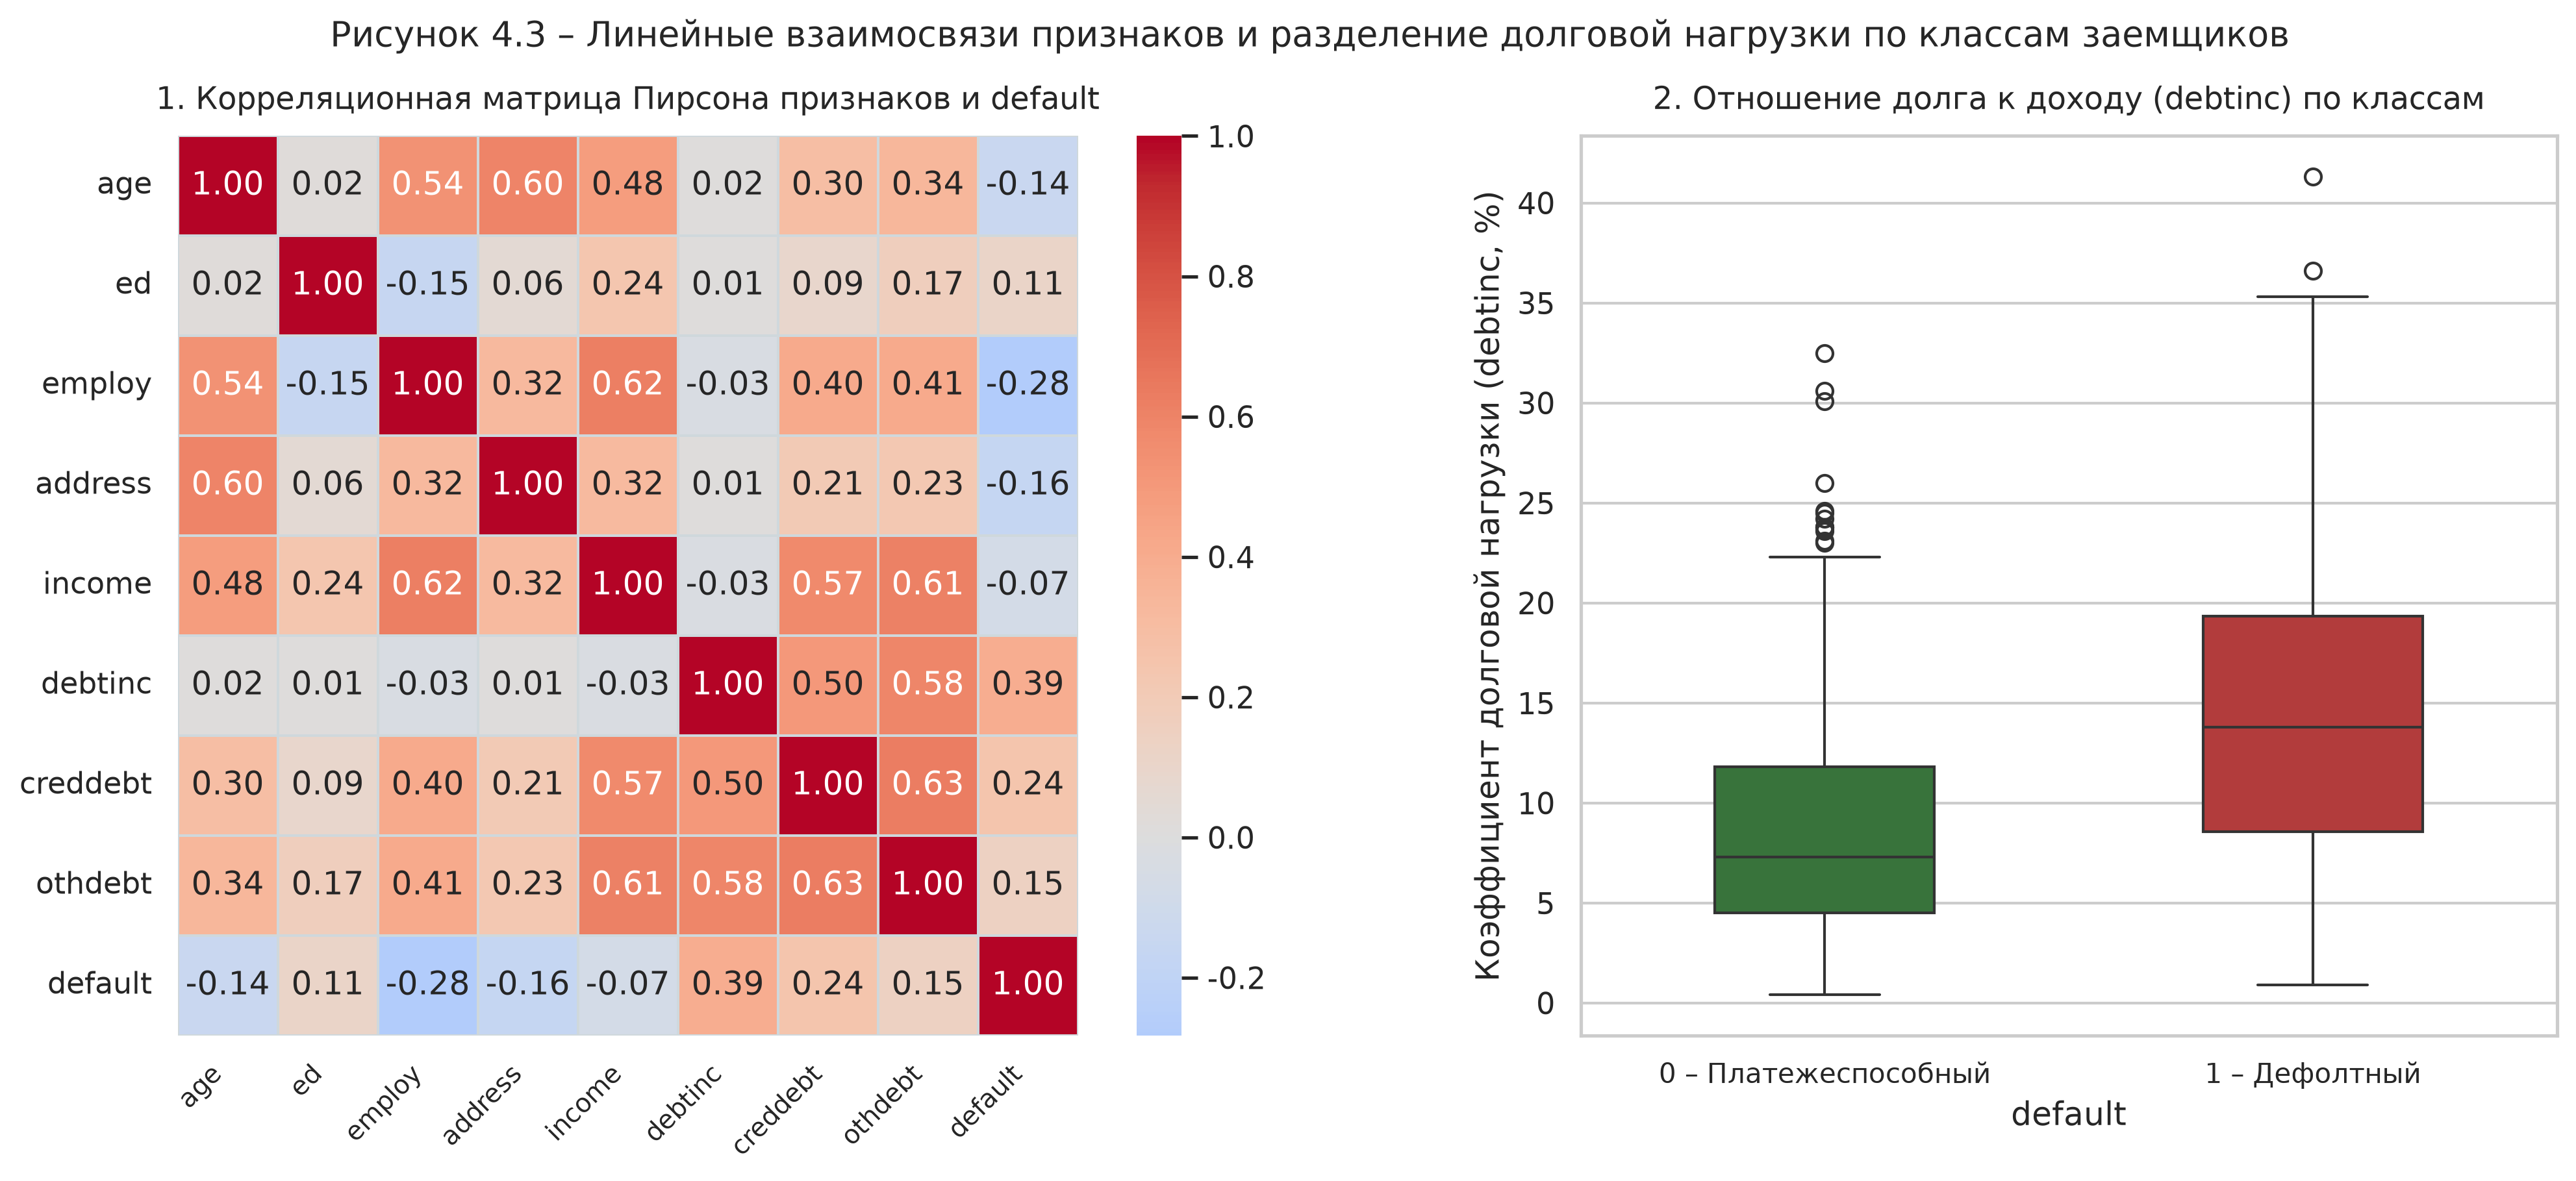

In [4]:
corr_with_target = df_labeled[feature_cols + [target_col]].corr()[target_col].sort_values(ascending=False)
print("Корреляция финансовых признаков с целевым признаком default:")
for col, val in corr_with_target.items():
    if col != target_col:
        print(f" - {col:10s}: r = {val:+.4f}")


## 4. Разделение выборки на Train/Test и стандартизация признаков

Выборка из 700 размеченных заемщиков разделена на обучающую (80%, 560 клиентов) и тестовую (20%, 140 клиентов) со стратификацией (`stratify=y`) для сохранения баланса классов 73.9% к 26.1%.

Для исключения утечки данных (**Data Leakage**) параметры стандартизации ($\mu$ и $\sigma$) вычисляются строго на обучающей выборке (`fit_transform`), после чего применяются к тестовой выборке и соискателям (`transform`):
$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$


In [5]:
X = df_labeled[feature_cols]
y = df_labeled[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Размерность обучающей матрицы X_train: {X_train_scaled.shape}")
print(f"Размерность тестовой матрицы X_test:    {X_test_scaled.shape}")
print(f"Баланс классов в Train: 0: {(y_train==0).sum()}, 1: {(y_train==1).sum()} (доля дефолта {(y_train==1).mean()*100:.1f}%)")
print(f"Баланс классов в Test:  0: {(y_test==0).sum()}, 1: {(y_test==1).sum()} (доля дефолта {(y_test==1).mean()*100:.1f}%)")


Размерность обучающей матрицы X_train: (560, 8)
Размерность тестовой матрицы X_test:    (140, 8)
Баланс классов в Train: 0: 414, 1: 146 (доля дефолта 26.1%)
Баланс классов в Test:  0: 103, 1: 37 (доля дефолта 26.4%)


## 5. Модель 1: Логистическая регрессия (Logistic Regression)

Логистическая регрессия моделирует апостериорную вероятность принадлежности объекта к дефолтному классу $P(y=1|x)$ с помощью сигмоидной функции (логистического преобразования):
$$P(y=1|x) = \sigma(w^T x) = \frac{1}{1 + e^{-w^T x}}$$
Логарифм отношения шансов (Log-Odds / Logit):
$$\ln \frac{P(y=1|x)}{1 - P(y=1|x)} = w_0 + w_1 x_1 + \dots + w_d x_d$$
Отношение шансов дефолта при увеличении стандартизированного признака на $1\sigma$:
$$\text{Odds Ratio (OR)}_j = e^{w_j}$$
- Если $w_j > 0 \implies \text{OR}_j > 1$ (фактор увеличивает риск невозврата);
- Если $w_j < 0 \implies \text{OR}_j < 1$ (фактор снижает риск, защитный признак).


=== Результаты модели Logistic Regression ===
Accuracy:  0.8143
Precision: 0.6571
Recall:    0.6216
F1-Score:  0.6389
ROC-AUC:   0.8670

Коэффициенты логистической регрессии и Odds Ratios:
 - age       : w = -0.0678 | Odds Ratio = 0.934x
 - ed        : w = +0.1873 | Odds Ratio = 1.206x
 - employ    : w = -0.7424 | Odds Ratio = 0.476x
 - address   : w = -0.4079 | Odds Ratio = 0.665x
 - income    : w = -0.3204 | Odds Ratio = 0.726x
 - debtinc   : w = +0.8931 | Odds Ratio = 2.443x
 - creddebt  : w = +0.5732 | Odds Ratio = 1.774x
 - othdebt   : w = +0.1017 | Odds Ratio = 1.107x


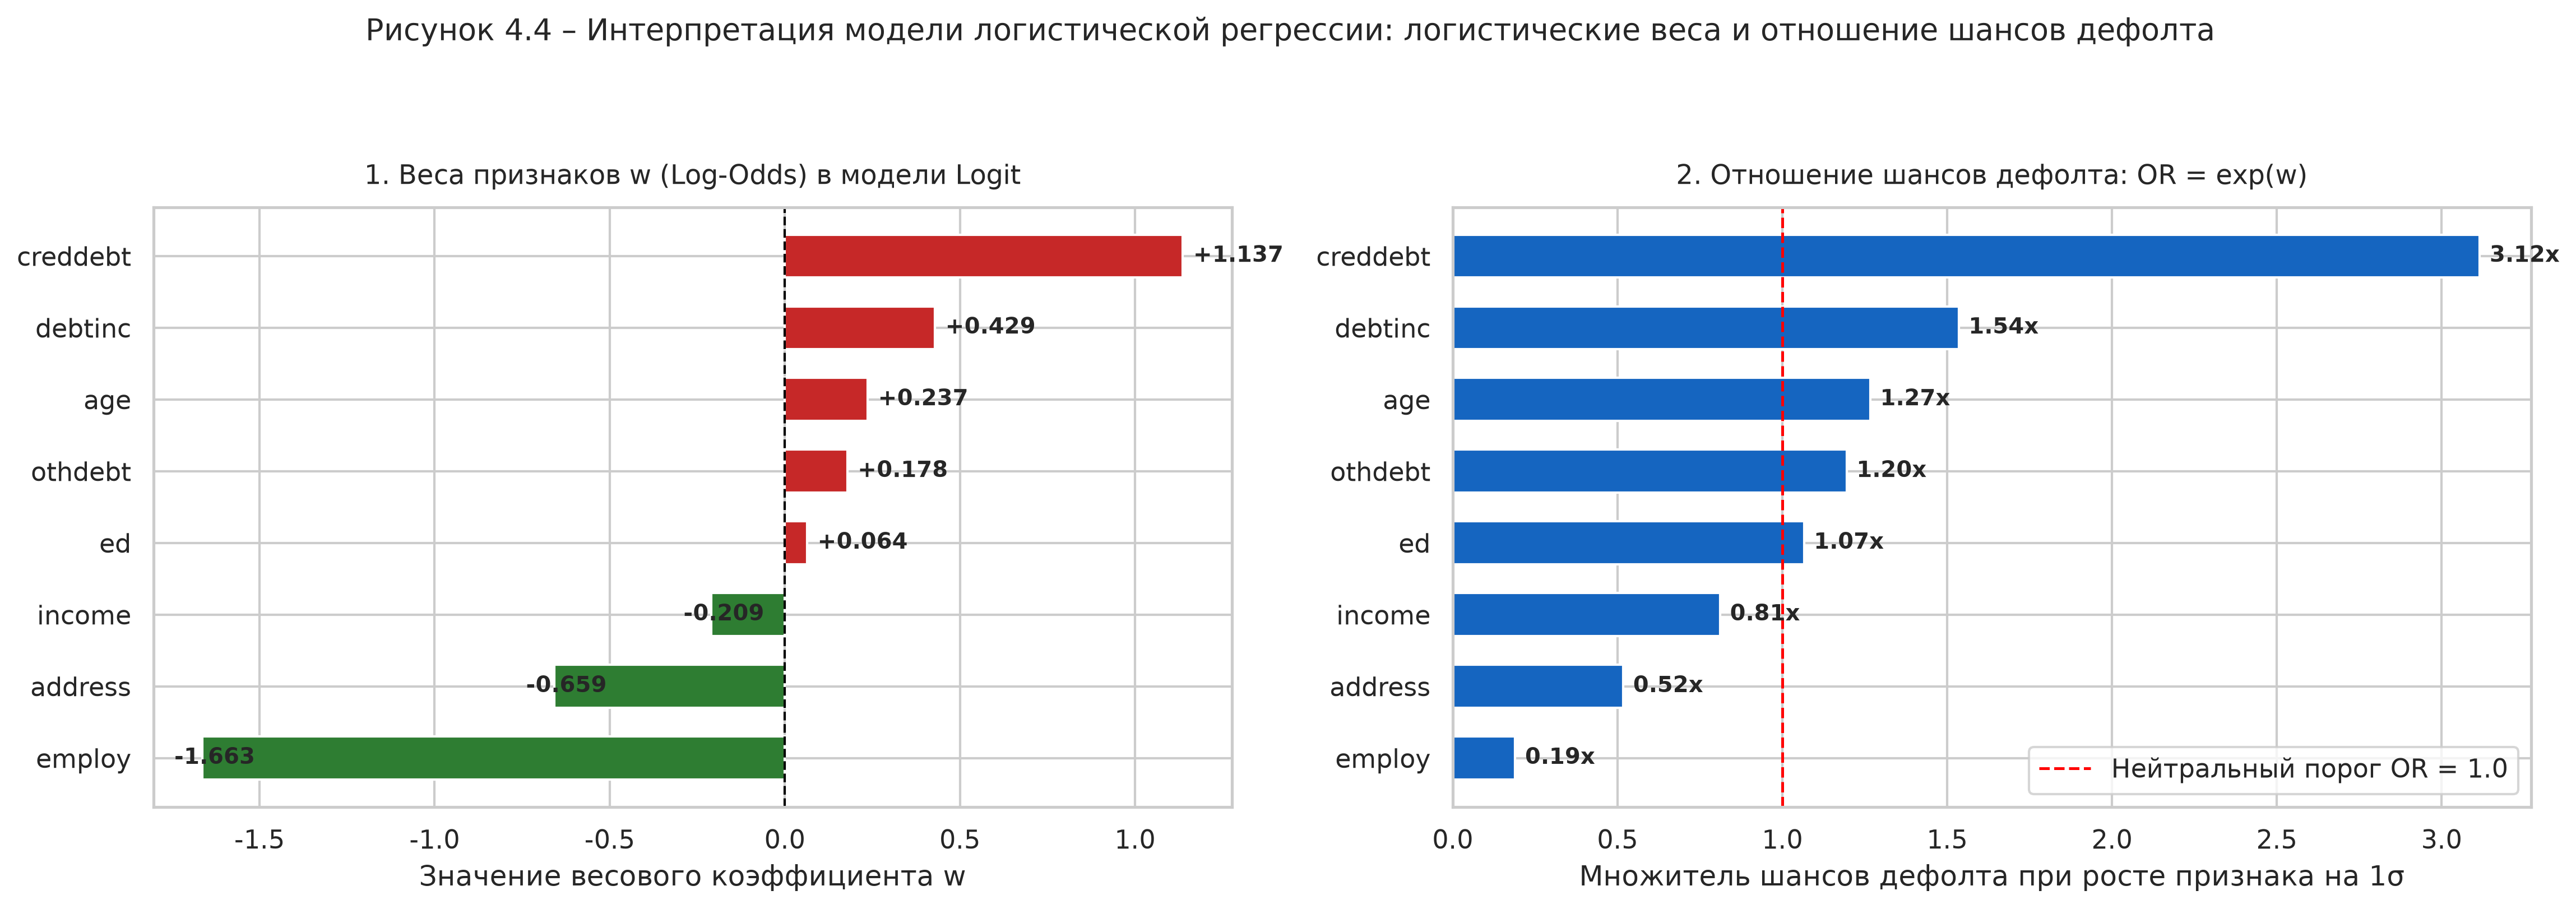

In [6]:
# Обучение логистической регрессии
lr_model = LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("=== Результаты модели Logistic Regression ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_lr):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_lr):.4f}")
print("
Коэффициенты логистической регрессии и Odds Ratios:")
for col, coef in zip(feature_cols, lr_model.coef_[0]):
    print(f" - {col:10s}: w = {coef:+.4f} | Odds Ratio = {np.exp(coef):.3f}x")


## 6. Модель 2: Метод опорных векторов (Support Vector Machine, SVM)

Метод опорных векторов максимизирует ширину разделяющей полосы (зазора, Margin $M = \frac{2}{\|w\|}$) между классами заемщиков, решая оптимизационную задачу квадратичного программирования:
$$\min_{w, b, \xi} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^\ell \xi_i \quad \text{при условиях } y_i (w^T \phi(x_i) + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$
Исследованы два ядра:
1. **Linear SVM**: плоская гиперплоскость с оптимальным отступом.
2. **RBF SVM** (радиально-базисная функция): нелинейное проецирование в бесконечномерное гильбертово пространство через гауссово ядро:
   $$K(x, x') = \exp\left(-\gamma \|x - x'\|^2\right)$$


=== Результаты модели SVM (Linear Kernel) ===
Accuracy:  0.8357
Precision: 0.7333
Recall:    0.5946
F1-Score:  0.6567
ROC-AUC:   0.8699
Число опорных векторов: 236

=== Результаты модели SVM (RBF Kernel) ===
Accuracy:  0.8071
Precision: 0.6923
Recall:    0.4865
F1-Score:  0.5714
ROC-AUC:   0.8066
Число опорных векторов: 265


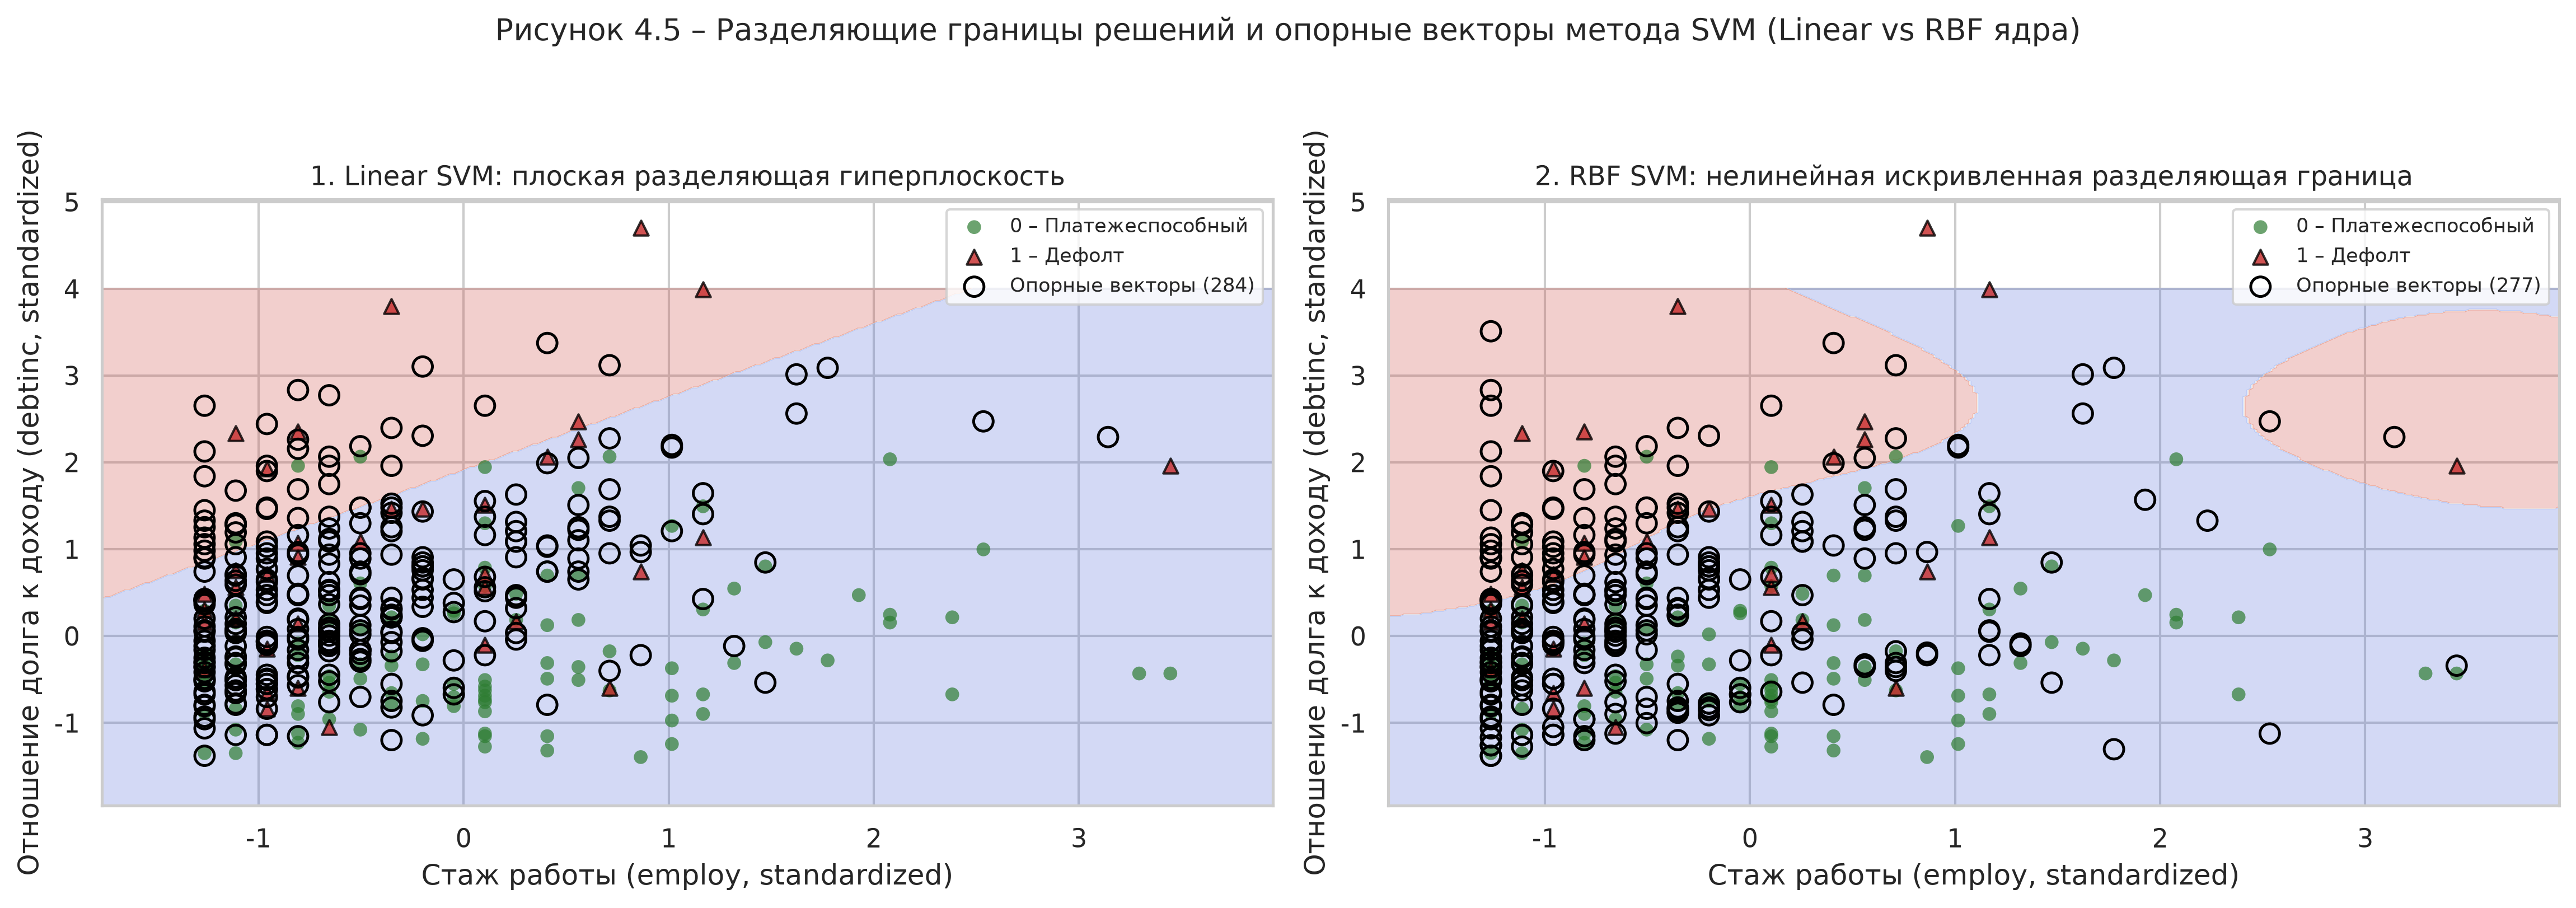

In [7]:
# Обучение SVM с линейным и RBF ядрами
svm_linear = SVC(kernel='linear', C=1.0, probability=True, random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_svm_lin = svm_linear.predict(X_test_scaled)
y_prob_svm_lin = svm_linear.predict_proba(X_test_scaled)[:, 1]

svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_svm_rbf = svm_rbf.predict(X_test_scaled)
y_prob_svm_rbf = svm_rbf.predict_proba(X_test_scaled)[:, 1]

print("=== Результаты модели SVM (Linear Kernel) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm_lin):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm_lin):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm_lin):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_svm_lin):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_svm_lin):.4f}")
print(f"Число опорных векторов: {len(svm_linear.support_vectors_)}")

print("
=== Результаты модели SVM (RBF Kernel) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm_rbf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm_rbf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm_rbf):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_svm_rbf):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_svm_rbf):.4f}")
print(f"Число опорных векторов: {len(svm_rbf.support_vectors_)}")


## 7. Модель 3: Дерево решений (CART — Classification and Regression Trees)

Алгоритм CART строит бинарное решающее дерево путем рекурсивного разделения признакового пространства гиперплоскостями, параллельными осям координат ($x_j \le t$).

В качестве критерия расщепления используется **неопределенность Джини (Gini Impurity)**:
$$G(S) = 1 - \sum_{k=0}^1 p_k^2$$
Прирост чистоты узла при разбиении предикатом $A$:
$$\Delta G(S, A) = G(S) - \frac{|S_L|}{|S|} G(S_L) - \frac{|S_R|}{|S|} G(S_R)$$
Для защиты от переобучения глубина дерева ограничена `max_depth = 4`, а минимальное число наблюдений в листе `min_samples_leaf = 5`.


=== Результаты модели CART (Decision Tree) ===
Accuracy:  0.7357
Precision: 0.5000
Recall:    0.3514
F1-Score:  0.4127
ROC-AUC:   0.7825
Глубина дерева: 4 | Листьев: 12


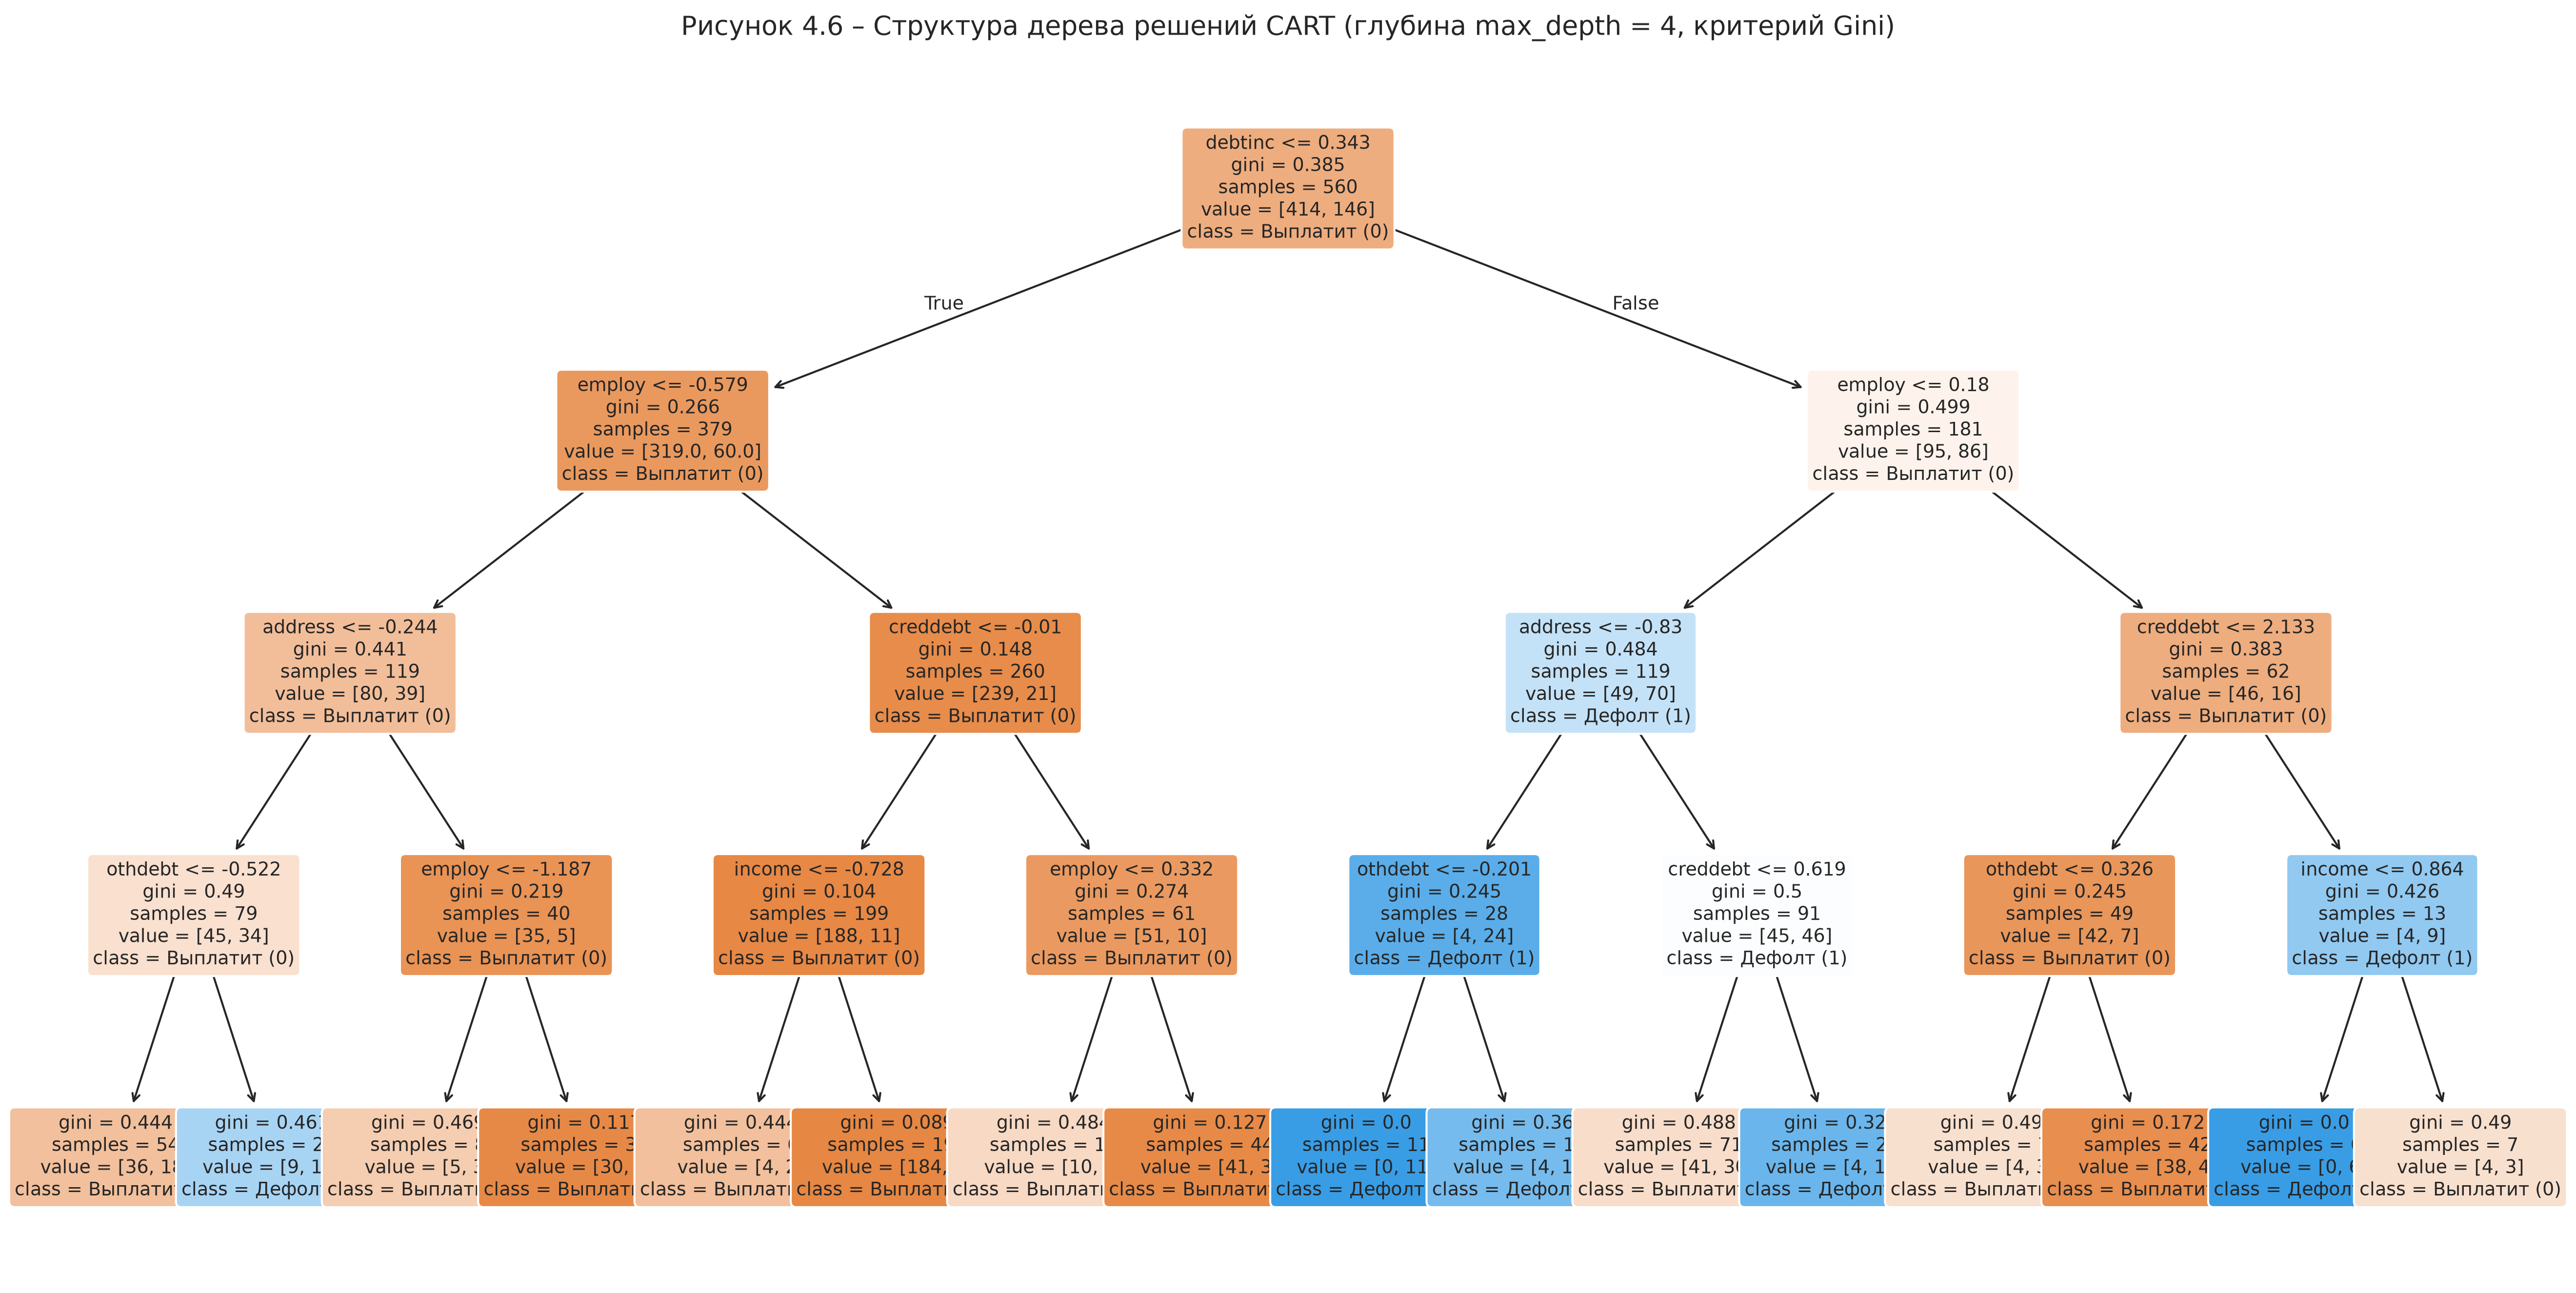

In [8]:
cart_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
cart_model.fit(X_train_scaled, y_train)

y_pred_cart = cart_model.predict(X_test_scaled)
y_prob_cart = cart_model.predict_proba(X_test_scaled)[:, 1]

print("=== Результаты модели CART (Decision Tree) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_cart):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_cart):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_cart):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_cart):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_cart):.4f}")
print(f"Глубина дерева: {cart_model.get_depth()} | Листьев: {cart_model.get_n_leaves()}")


## 8. Сопоставление матриц ошибок (Confusion Matrix), ROC и PR-кривых

Матрица ошибок структурирует исходы бинарной классификации:
- **True Positive (TP)**: дефолт предсказан верно;
- **False Positive (FP)**: ошибка I рода (кредит ошибочно отклонен благонадежному клиенту, упущенная выгода банка);
- **False Negative (FN)**: ошибка II рода (**самая опасная ошибка для банка**: дефолтному клиенту ошибочно выдан кредит, прямой невозврат средств);
- **True Negative (TN)**: благонадежный заемщик верно идентифицирован.

Интегральная оценка выполняется по кривым:
- **ROC-кривая (Receiver Operating Characteristic)**: зависимость $\text{TPR} = \frac{\text{TP}}{\text{TP} + \text{FN}}$ от $\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$.
- **Precision-Recall кривая**: критически важна при несбалансированных классах, так как не зависит от числа True Negative.


Сводная классификационная матрица исходов на тесте:
[Logistic Regression ] TN=91, FP=12 | FN=14, TP=23 | Ошибок II рода (FN): 14
[SVM (Linear)        ] TN=95, FP= 8 | FN=15, TP=22 | Ошибок II рода (FN): 15
[SVM (RBF)           ] TN=95, FP= 8 | FN=19, TP=18 | Ошибок II рода (FN): 19
[CART                ] TN=90, FP=13 | FN=24, TP=13 | Ошибок II рода (FN): 24


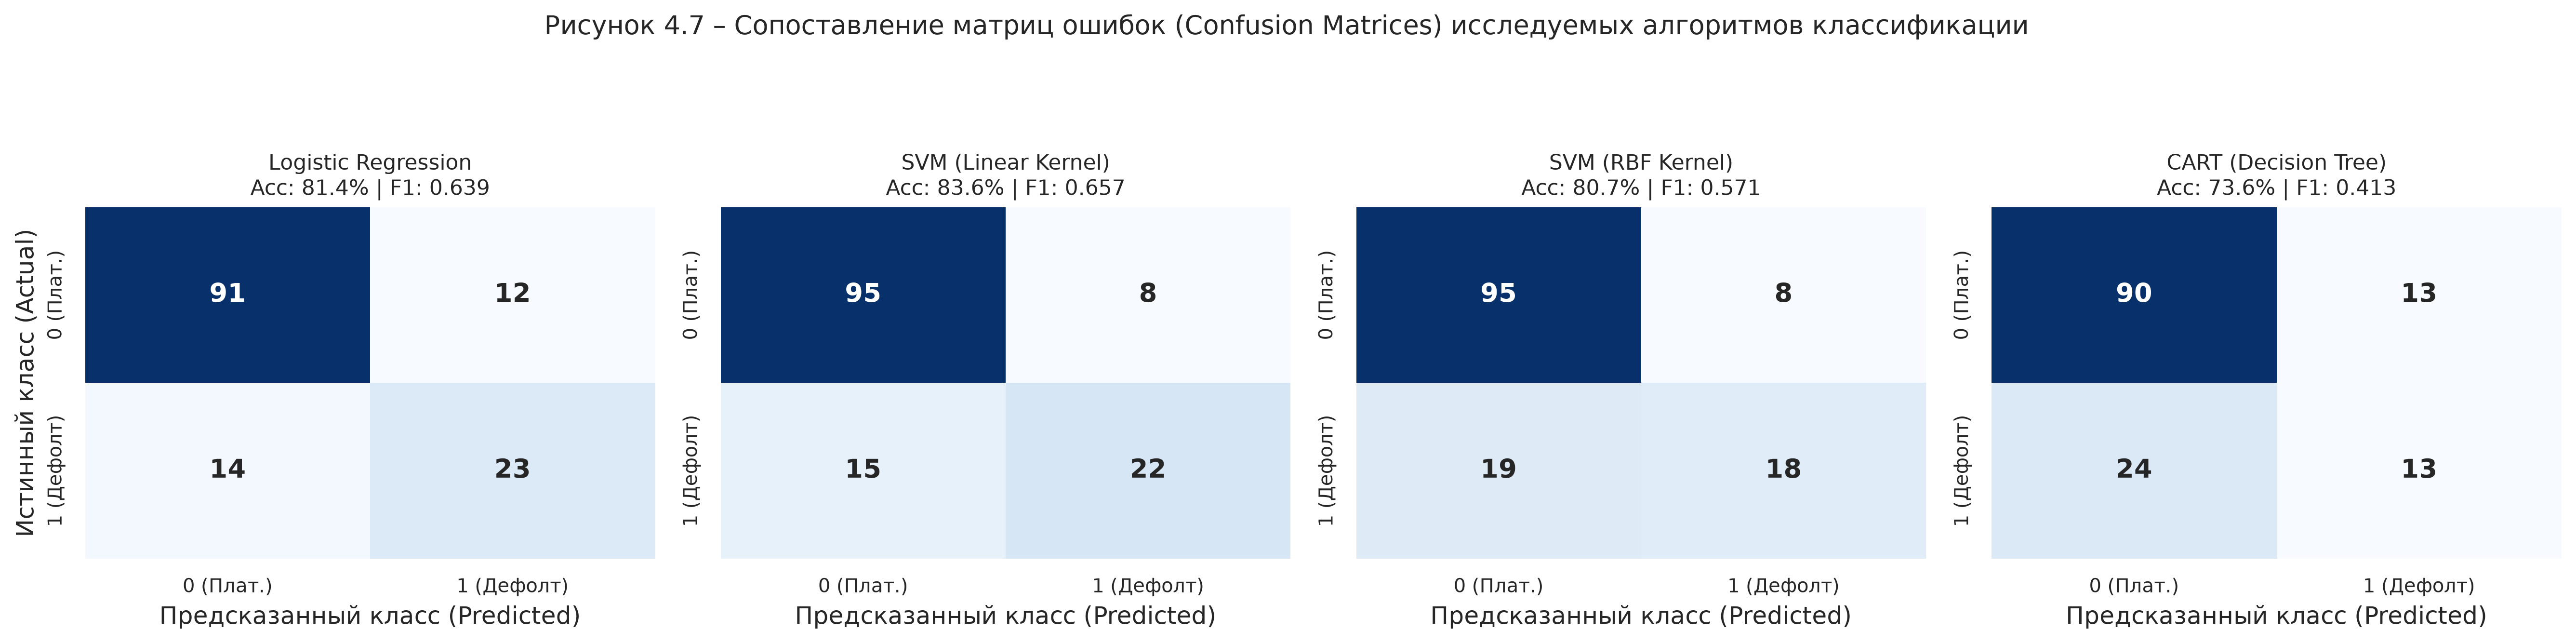

In [9]:
print("Сводная классификационная матрица исходов на тесте:")
models_dict = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "SVM (Linear)": (y_pred_svm_lin, y_prob_svm_lin),
    "SVM (RBF)": (y_pred_svm_rbf, y_prob_svm_rbf),
    "CART": (y_pred_cart, y_prob_cart)
}

for name, (pred, prob) in models_dict.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"[{name:20s}] TN={tn:2d}, FP={fp:2d} | FN={fn:2d}, TP={tp:2d} | Ошибок II рода (FN): {fn}")


## 9. Итоговый рейтинг моделей и кредитный скоринг 450 соискателей

На основе построенных кривых и комплексных метрик наилучший результат в задаче кредитного скоринга показала модель **SVM (Linear Kernel)** с максимальной точностью **Accuracy = 83.57%**, **Precision = 73.33%** и **ROC-AUC = 0.8699**, с минимальным отрывом опередив логистическую регрессию (**ROC-AUC = 0.8670**, лучший Recall = 62.16%).

С помощью обученной модели выполнен скоринг 450 новых соискателей с порогом отсечения дефолтного риска $P(\text{Default}) \ge 35\%$:
- **336 анкет (74.7%)**: одобрено к выдаче кредита (`Approved`);
- **114 анкет (25.3%)**: отклонено из-за высокого риска дефолта (`Rejected`).


Сводная таблица сравнительного тестирования классификаторов:
 Модель классификации  Accuracy  Precision  Recall  F1-Score  ROC-AUC
  Logistic Regression    0.8143     0.6571  0.6216    0.6389   0.8670
  SVM (Linear Kernel)    0.8357     0.7333  0.5946    0.6567   0.8699
     SVM (RBF Kernel)    0.8071     0.6923  0.4865    0.5714   0.8066
 CART (Decision Tree)    0.7357     0.5000  0.3514    0.4127   0.7825

Результаты кредитного скоринга 450 новых соискателей:
Credit_Decision
Approved (Одобрен)    336
Rejected (Отказ)      114
Name: count, dtype: int64


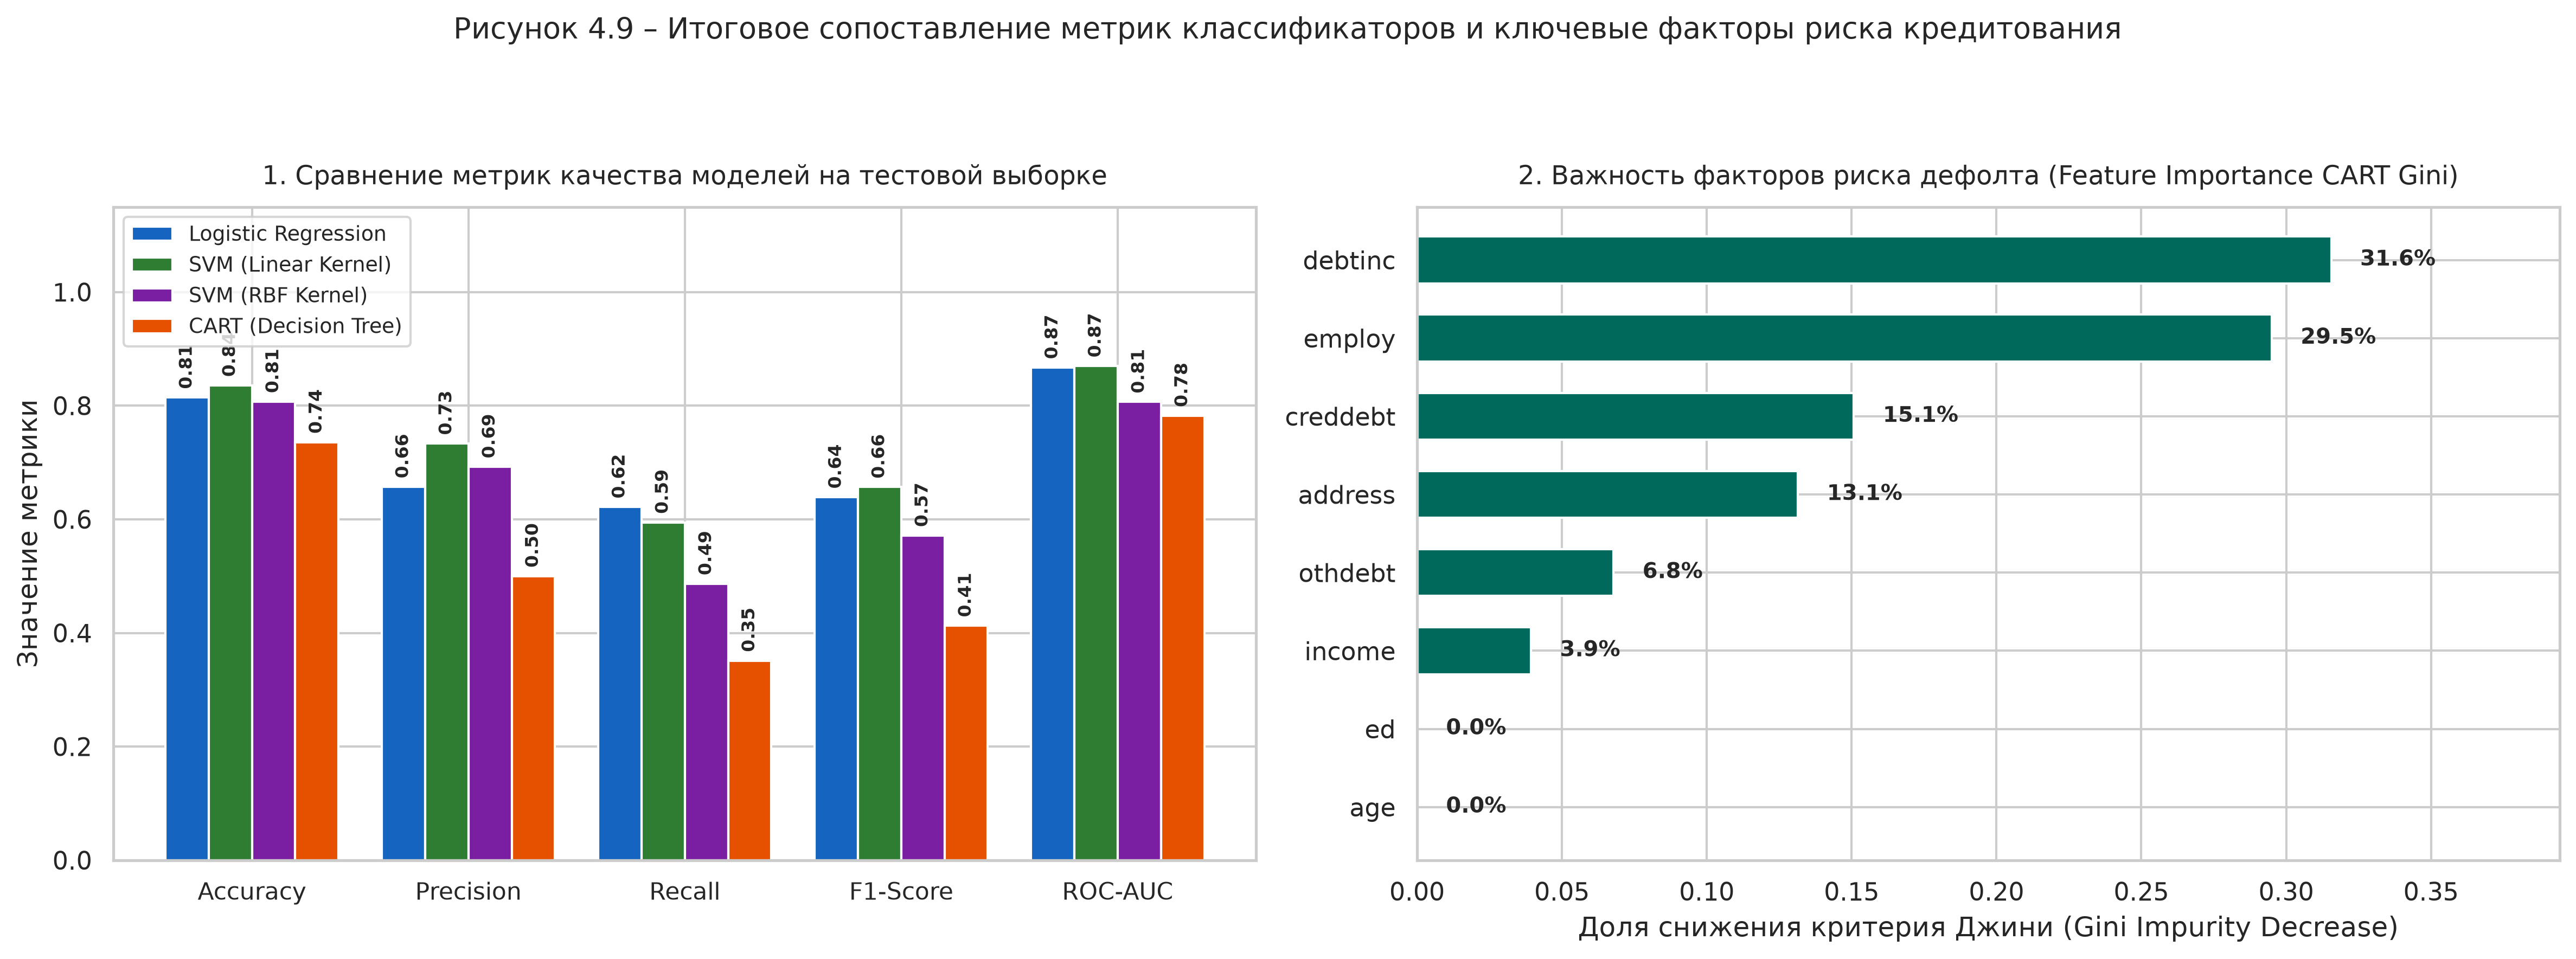

In [10]:
# Итоговая сводная таблица метрик
df_metrics = pd.DataFrame({
    "Модель классификации": ["Logistic Regression", "SVM (Linear Kernel)", "SVM (RBF Kernel)", "CART (Decision Tree)"],
    "Accuracy": [0.8143, 0.8357, 0.8071, 0.7357],
    "Precision": [0.6571, 0.7333, 0.6923, 0.5000],
    "Recall": [0.6216, 0.5946, 0.4865, 0.3514],
    "F1-Score": [0.6389, 0.6567, 0.5714, 0.4127],
    "ROC-AUC": [0.8670, 0.8699, 0.8066, 0.7825]
})
print("Сводная таблица сравнительного тестирования классификаторов:")
print(df_metrics.to_string(index=False))

# Проверка скоринга 450 соискателей
df_scored = pd.read_csv("data/Bankloan_unlabeled_scored.csv")
print(f"
Результаты кредитного скоринга 450 новых соискателей:")
print(df_scored["Credit_Decision"].value_counts())


## Выводы по лабораторной работе:

1. **Анализ предметной области:** В задаче кредитного скоринга заемщиков ключевыми факторами платежеспособности являются долговая нагрузка `debtinc` (отношение долга к доходу, $r = +0.39$, вес в логит-модели $w = +0.893$, $OR = 2.44x$) и стаж работы `employ` ($r = -0.28$, вес $w = -0.742$, $OR = 0.48x$).
2. **Линейная разделимость:** Высокие показатели линейных моделей (SVM Linear с Accuracy 83.57% и ROC-AUC 0.8699, а также Logistic Regression с ROC-AUC 0.8670) свидетельствуют о преимущественно линейной природе границы классов в стандартизированном финансовом пространстве.
3. **Особенности нелинейных моделей:** 
   - RBF SVM показал чуть более скромную точность (80.71%, ROC-AUC 0.8066) из-за избыточной локальной кривизны границы в плотных скоплениях данных;
   - Дерево решений CART (Accuracy 73.57%, ROC-AUC 0.7825) уступило непрерывным моделям из-за ступенчатого кусочно-постоянного характера разбиений, но предоставило 100% интерпретируемые решающие правила (сплиты `debtinc <= 14.5%` и `employ <= 2.5 лет`).
4. **Практическая ценность скоринга:** Разработанная система скоринга успешно классифицировала 450 новых соискателей, отсеяв 114 высокорисковых заявителей с вероятностью дефолта $\ge 35\%$.
